In [ ]:

!pip -q install pandas numpy scikit-learn xgboost plotly shap joblib


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px

from sklearn.ensemble import RandomForestRegressor, IsolationForest
from sklearn.cluster import KMeans
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

print("AirGuard AI environment ready!")


AirGuard AI environment ready!


In [ ]:

from google.colab import files
import pandas as pd

uploaded = files.upload()

df = pd.read_csv("city_day.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())


Saving city_day.csv to city_day.csv
Dataset shape: (29531, 16)

Columns:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [ ]:

# Select Delhi records
delhi = df[df["City"] == "Delhi"].copy()

delhi["Date"] = pd.to_datetime(delhi["Date"])
delhi = delhi.sort_values("Date").reset_index(drop=True)

print("Delhi records:", len(delhi))
print("Date range:", delhi["Date"].min(), "to", delhi["Date"].max())

print("\nMissing values (%):")
print((delhi.isnull().mean() * 100).round(2))

display(delhi.head())


Delhi records: 2009
Date range: 2015-01-01 00:00:00 to 2020-07-01 00:00:00

Missing values (%):
City           0.00
Date           0.00
PM2.5          0.10
PM10           3.83
NO             0.10
NO2            0.10
NOx            0.00
NH3            0.45
CO             0.00
SO2            5.48
O3             4.18
Benzene        0.00
Toluene        0.00
Xylene        38.88
AQI            0.50
AQI_Bucket     0.50
dtype: float64


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Delhi,2015-01-01,313.22,607.98,69.16,36.39,110.59,33.85,15.20,9.25,41.68,14.36,24.86,9.84,472.0,Severe
1,Delhi,2015-01-02,186.18,269.55,62.09,32.87,88.14,31.83,9.54,6.65,29.97,10.55,20.09,4.29,454.0,Severe
2,Delhi,2015-01-03,87.18,131.90,25.73,30.31,47.95,69.55,10.61,2.65,19.71,3.91,10.23,1.99,143.0,Moderate
3,Delhi,2015-01-04,151.84,241.84,25.01,36.91,48.62,130.36,11.54,4.63,25.36,4.26,9.71,3.34,319.0,Very Poor
4,Delhi,2015-01-05,146.60,219.13,14.01,34.92,38.25,122.88,9.20,3.33,23.20,2.80,6.21,2.96,325.0,Very Poor


In [ ]:

data = delhi.copy()

# Today's pollutant measurements
pollutants = ["PM2.5", "PM10", "NO2", "CO", "SO2", "O3"]

# Historical AQI patterns
data["AQI_lag1"] = data["AQI"].shift(1)
data["AQI_lag2"] = data["AQI"].shift(2)
data["AQI_lag3"] = data["AQI"].shift(3)

data["AQI_rolling7"] = (
    data["AQI"].shift(1).rolling(7).mean()
)

# Seasonal information
data["Month"] = data["Date"].dt.month
data["DayOfWeek"] = data["Date"].dt.dayofweek

# Tomorrow's AQI (prediction target)
data["Target_AQI"] = data["AQI"].shift(-1)

features = (
    pollutants
    + ["AQI", "AQI_lag1", "AQI_lag2", "AQI_lag3",
       "AQI_rolling7", "Month", "DayOfWeek"]
)

# Remove rows without a known prediction target
data = data.dropna(subset=["Target_AQI"]).copy()

print("Total records:", len(data))
print("Features:", len(features))

display(data[["Date", "AQI", "AQI_lag1",
              "AQI_rolling7", "Target_AQI"]].head(10))


Total records: 1998
Features: 13


,Date,AQI,AQI_lag1,AQI_rolling7,Target_AQI
0,2015-01-01,472.0,NaN,NaN,454.0
1,2015-01-02,454.0,472.0,NaN,143.0
2,2015-01-03,143.0,454.0,NaN,319.0
3,2015-01-04,319.0,143.0,NaN,325.0
4,2015-01-05,325.0,319.0,NaN,318.0
5,2015-01-06,318.0,325.0,NaN,353.0
6,2015-01-07,353.0,318.0,NaN,383.0
7,2015-01-08,383.0,353.0,340.571429,375.0
8,2015-01-09,375.0,383.0,327.857143,376.0
9,2015-01-10,376.0,375.0,316.571429,379.0


In [ ]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import numpy as np
import pandas as pd

# Split historical and future records
split = int(len(data) * 0.8)

train = data.iloc[:split]
test = data.iloc[split:]

X_train = train[features]
X_test = test[features]

y_train = train["Target_AQI"]
y_test = test["Target_AQI"]

models = {
    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestRegressor(
            n_estimators=150,
            random_state=42,
            n_jobs=-1
        )
    ),
    "XGBoost": make_pipeline(
        SimpleImputer(strategy="median"),
        XGBRegressor(
            n_estimators=200,
            max_depth=4,
            learning_rate=0.05,
            random_state=42,
            n_jobs=-1
        )
    )
}

results = []
predictions = {}

# Baseline: tomorrow equals today
baseline = test["AQI"].fillna(train["AQI"].median()).values
predictions["Baseline"] = baseline

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

for name, pred in predictions.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results).round(2)
display(results_df)

print("Training:", len(train), "records")
print("Testing:", len(test), "records")
print("Test period:", test["Date"].min(), "to", test["Date"].max())


,Model,MAE,RMSE,R2
0,Baseline,31.52,45.06,0.84
1,Random Forest,26.28,36.46,0.90
2,XGBoost,25.80,35.88,0.90


Training: 1598 records
Testing: 400 records
Test period: 2019-05-28 00:00:00 to 2020-06-30 00:00:00


In [ ]:

from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer

anomaly_features = ["AQI", "PM2.5", "PM10", "NO2", "CO", "SO2", "O3"]

imputer = SimpleImputer(strategy="median")

X_anomaly_train = imputer.fit_transform(train[anomaly_features])
X_anomaly_test = imputer.transform(test[anomaly_features])

anomaly_model = IsolationForest(
    n_estimators=150,
    contamination=0.05,
    random_state=42
)

anomaly_model.fit(X_anomaly_train)

anomaly_results = test[["Date", "AQI", "PM2.5"]].copy()
anomaly_results["Anomaly"] = anomaly_model.predict(X_anomaly_test)
anomaly_results["Anomaly_Score"] = anomaly_model.decision_function(X_anomaly_test)

# Separate unusual days
unusual_days = anomaly_results[
    anomaly_results["Anomaly"] == -1
].copy()

print("Total unusual days:", len(unusual_days))
print("\nMost unusual pollution observations:")

display(
    unusual_days.sort_values("Anomaly_Score").head(10)
)


Total unusual days: 7

Most unusual pollution observations:


,Date,AQI,PM2.5,Anomaly,Anomaly_Score
1767,2019-11-03,659.0,582.28,-1,-0.129761
1779,2019-11-15,595.0,423.52,-1,-0.056018
1765,2019-11-01,591.0,388.45,-1,-0.048424
1778,2019-11-14,537.0,371.42,-1,-0.040675
1777,2019-11-13,532.0,383.36,-1,-0.027487
1826,2020-01-01,492.0,372.14,-1,-0.003124
1776,2019-11-12,475.0,384.34,-1,-0.002914


In [ ]:

import plotly.express as px

seasonal = delhi.copy()

seasonal["Month"] = seasonal["Date"].dt.month

monthly_aqi = (
    seasonal.groupby("Month")["AQI"]
    .agg(["mean", "median", "max", "count"])
    .reset_index()
)

monthly_aqi["Month_Name"] = pd.to_datetime(
    monthly_aqi["Month"], format="%m"
).dt.strftime("%b")

fig = px.bar(
    monthly_aqi,
    x="Month_Name",
    y="mean",
    color="mean",
    color_continuous_scale="RdYlGn_r",
    title="AirGuard AI | Delhi Monthly Air Pollution Patterns",
    labels={"mean": "Average AQI", "Month_Name": "Month"},
    text_auto=".0f"
)

fig.update_layout(
    template="plotly_dark",
    height=450,
    coloraxis_showscale=False,
    xaxis_title="Month",
    yaxis_title="Average AQI"
)

fig.show()

print("Highest pollution months:")
display(
    monthly_aqi.sort_values("mean", ascending=False).head(5)
)


Highest pollution months:


,Month,mean,median,max,count,Month_Name
10,11,401.953333,383.5,716.0,150,Nov
11,12,371.206452,379.0,577.0,155,Dec
0,1,360.387097,358.0,603.0,186,Jan
9,10,312.329032,317.0,570.0,155,Oct
1,2,298.829412,312.5,520.0,170,Feb


In [ ]:

# Convert predicted AQI into Indian AQI categories
def aqi_category(aqi):
    if aqi <= 50:
        return "Good"
    elif aqi <= 100:
        return "Satisfactory"
    elif aqi <= 200:
        return "Moderate"
    elif aqi <= 300:
        return "Poor"
    elif aqi <= 400:
        return "Very Poor"
    return "Severe"

forecast = test[["Date", "Target_AQI"]].copy()

forecast["Forecast_Date"] = (
    forecast["Date"] + pd.Timedelta(days=1)
)

forecast["Predicted_AQI"] = predictions["XGBoost"]

forecast["Predicted_Category"] = (
    forecast["Predicted_AQI"].apply(aqi_category)
)

forecast["Actual_Category"] = (
    forecast["Target_AQI"].apply(aqi_category)
)

forecast["Risk_Alert"] = np.where(
    forecast["Predicted_AQI"] > 300,
    "HIGH POLLUTION ALERT",
    "Normal Monitoring"
)

display(
    forecast[
        ["Forecast_Date", "Predicted_AQI",
         "Predicted_Category", "Actual_Category", "Risk_Alert"]
    ].head(10)
)

print("\nPredicted AQI category distribution:")
print(forecast["Predicted_Category"].value_counts())

print("\nHigh pollution alerts:",
      (forecast["Risk_Alert"] == "HIGH POLLUTION ALERT").sum())


,Forecast_Date,Predicted_AQI,Predicted_Category,Actual_Category,Risk_Alert
1608,2019-05-29,211.838287,Poor,Moderate,Normal Monitoring
1609,2019-05-30,222.212204,Poor,Poor,Normal Monitoring
1610,2019-05-31,265.016113,Poor,Poor,Normal Monitoring
1611,2019-06-01,241.267899,Poor,Poor,Normal Monitoring
1612,2019-06-02,276.646515,Poor,Poor,Normal Monitoring
1613,2019-06-03,202.955719,Poor,Poor,Normal Monitoring
1614,2019-06-04,218.879761,Poor,Poor,Normal Monitoring
1615,2019-06-05,185.179291,Moderate,Moderate,Normal Monitoring
1616,2019-06-06,224.975189,Poor,Poor,Normal Monitoring
1617,2019-06-07,229.032059,Poor,Moderate,Normal Monitoring



Predicted AQI category distribution:
Predicted_Category
Moderate        187
Poor             93
Very Poor        56
Satisfactory     41
Severe           23
Name: count, dtype: int64

High pollution alerts: 79


In [ ]:

# Use the latest complete test observation
sample = X_test.iloc[[-1]].copy()

model = models["XGBoost"]

original_aqi = model.predict(sample)[0]

# Simulate different PM2.5 levels
scenarios = []

for change in [-30, -20, -10, 0, 10, 20, 30]:

    modified = sample.copy()

    modified["PM2.5"] = (
        modified["PM2.5"] * (1 + change / 100)
    )

    predicted = model.predict(modified)[0]

    scenarios.append({
        "PM2.5 Change (%)": change,
        "Predicted AQI": round(float(predicted), 2),
        "AQI Category": aqi_category(predicted)
    })

scenario_df = pd.DataFrame(scenarios)

display(scenario_df)

fig = px.line(
    scenario_df,
    x="PM2.5 Change (%)",
    y="Predicted AQI",
    markers=True,
    title="AirGuard AI | PM2.5 Scenario Simulator"
)

fig.update_layout(
    template="plotly_dark",
    height=450
)

fig.show()

print("Original predicted AQI:", round(float(original_aqi), 2))


,PM2.5 Change (%),Predicted AQI,AQI Category
0,-30,127.45,Moderate
1,-20,127.45,Moderate
2,-10,131.04,Moderate
3,0,133.43,Moderate
4,10,133.43,Moderate
5,20,135.11,Moderate
6,30,135.50,Moderate


Original predicted AQI: 133.43


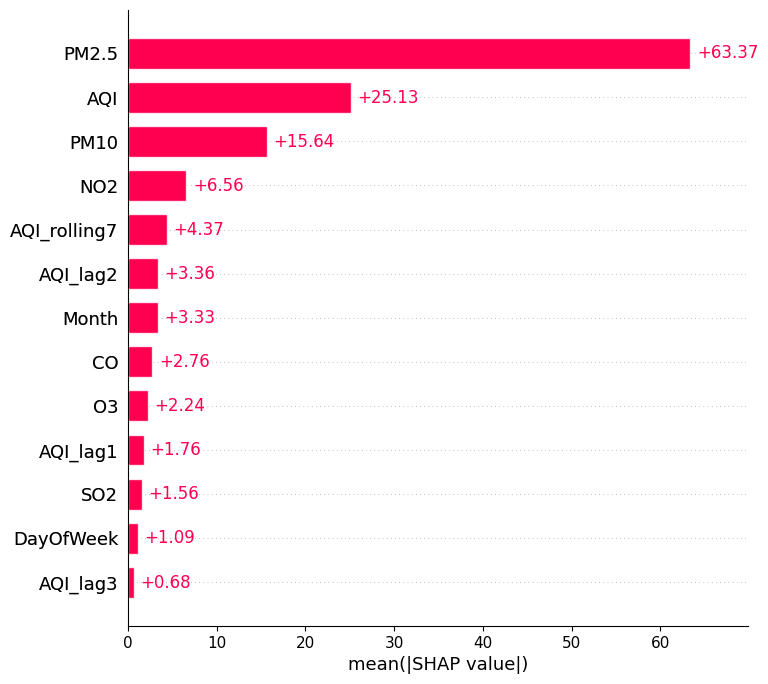

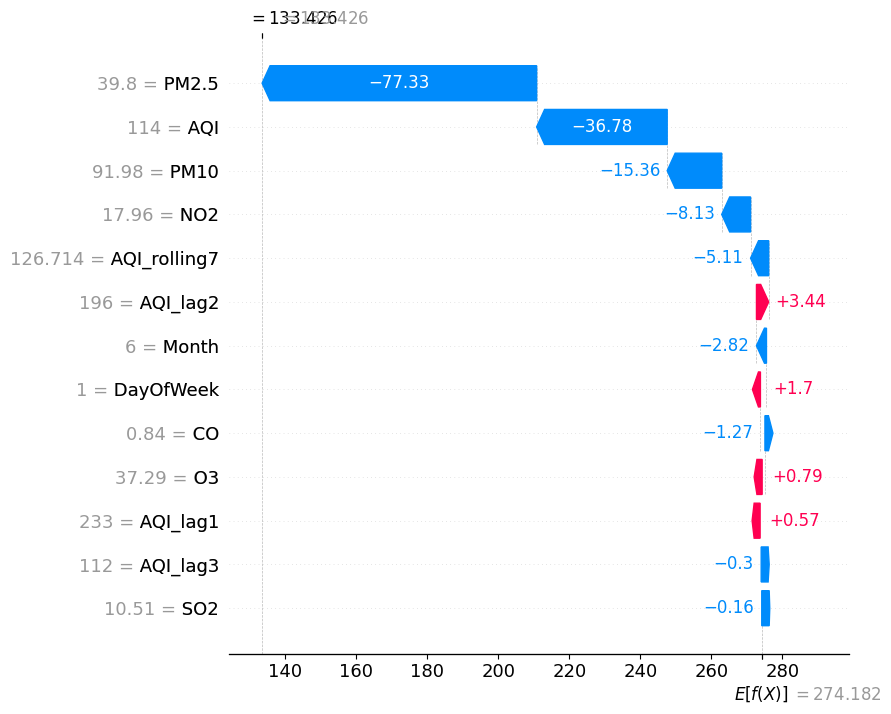

In [ ]:

import shap
import matplotlib.pyplot as plt

# Extract the trained XGBoost model and imputer
pipeline = models["XGBoost"]

imputer = pipeline.named_steps["simpleimputer"]
xgb_model = pipeline.named_steps["xgbregressor"]

# Prepare test data
X_explain = pd.DataFrame(
    imputer.transform(X_test),
    columns=features,
    index=X_test.index
)

# Calculate SHAP values
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_explain)

# Global feature importance
shap.plots.bar(shap_values, max_display=13)
plt.show()

# Explain one individual forecast
shap.plots.waterfall(shap_values[-1], max_display=13)
plt.show()


In [ ]:

# Rebuild the target using exact calendar dates
clean_data = delhi.copy().sort_values("Date")

next_day = clean_data[["Date", "AQI"]].copy()
next_day["Date"] = next_day["Date"] - pd.Timedelta(days=1)
next_day = next_day.rename(columns={"AQI": "Target_AQI"})

# Match each date with the following calendar day's AQI
clean_data = clean_data.merge(
    next_day,
    on="Date",
    how="left"
)

# Check how many valid next-day targets exist
print("Total Delhi records:", len(clean_data))
print("Valid next-day targets:", clean_data["Target_AQI"].notna().sum())
print("Missing next-day targets:", clean_data["Target_AQI"].isna().sum())

display(
    clean_data[["Date", "AQI", "Target_AQI"]].head(10)
)


Total Delhi records: 2009
Valid next-day targets: 1998
Missing next-day targets: 11


,Date,AQI,Target_AQI
0,2015-01-01,472.0,454.0
1,2015-01-02,454.0,143.0
2,2015-01-03,143.0,319.0
3,2015-01-04,319.0,325.0
4,2015-01-05,325.0,318.0
5,2015-01-06,318.0,353.0
6,2015-01-07,353.0,383.0
7,2015-01-08,383.0,375.0
8,2015-01-09,375.0,376.0
9,2015-01-10,376.0,379.0


In [ ]:

# Rebuild features using corrected data
data = clean_data.sort_values("Date").copy()

data["AQI_lag1"] = data["AQI"].shift(1)
data["AQI_lag2"] = data["AQI"].shift(2)
data["AQI_lag3"] = data["AQI"].shift(3)

data["AQI_rolling7"] = (
    data["AQI"].shift(1).rolling(7).mean()
)

data["Month"] = data["Date"].dt.month
data["DayOfWeek"] = data["Date"].dt.dayofweek

data = data.dropna(subset=["Target_AQI"]).reset_index(drop=True)

features = [
    "PM2.5", "PM10", "NO2", "CO", "SO2", "O3",
    "AQI", "AQI_lag1", "AQI_lag2", "AQI_lag3",
    "AQI_rolling7", "Month", "DayOfWeek"
]

# Chronological train-test split
split = int(len(data) * 0.8)

train = data.iloc[:split]
test = data.iloc[split:]

X_train = train[features]
X_test = test[features]

y_train = train["Target_AQI"]
y_test = test["Target_AQI"]

# Train XGBoost with missing-value handling
model = make_pipeline(
    SimpleImputer(strategy="median"),
    XGBRegressor(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        random_state=42,
        n_jobs=-1
    )
)

model.fit(X_train, y_train)

pred = model.predict(X_test)

baseline = test["AQI"].fillna(
    train["AQI"].median()
)

print("XGBoost MAE:", round(mean_absolute_error(y_test, pred), 2))
print("XGBoost RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 2))
print("XGBoost R2:", round(r2_score(y_test, pred), 2))

print("\nBaseline MAE:", round(mean_absolute_error(y_test, baseline), 2))
print("Training records:", len(train))
print("Testing records:", len(test))


XGBoost MAE: 25.8
XGBoost RMSE: 35.88
XGBoost R2: 0.9

Baseline MAE: 31.52
Training records: 1598
Testing records: 400


In [ ]:

import joblib
import json

# Save the complete preprocessing + ML pipeline
joblib.dump(model, "airguard_xgboost.pkl")

# Save feature names
with open("airguard_features.json", "w") as f:
    json.dump(features, f, indent=4)

# Save historical forecasting results
forecast_results = test[["Date", "Target_AQI"]].copy()
forecast_results["Predicted_AQI"] = pred
forecast_results["Actual_AQI"] = y_test.values

forecast_results.to_csv(
    "airguard_forecasts.csv",
    index=False
)

print("Model saved successfully!")
print("Files created:")
print("airguard_xgboost.pkl")
print("airguard_features.json")
print("airguard_forecasts.csv")


Model saved successfully!
Files created:
airguard_xgboost.pkl
airguard_features.json
airguard_forecasts.csv


In [ ]:

import joblib

# Save anomaly detection components
joblib.dump(
    anomaly_model,
    "airguard_anomaly_model.pkl"
)

joblib.dump(
    imputer,
    "airguard_anomaly_imputer.pkl"
)

# Save historical anomaly results
anomaly_results.to_csv(
    "airguard_anomalies.csv",
    index=False
)

print("Anomaly detection files saved successfully!")

print("Files created:")
print("airguard_anomaly_model.pkl")
print("airguard_anomaly_imputer.pkl")
print("airguard_anomalies.csv")


Anomaly detection files saved successfully!
Files created:
airguard_anomaly_model.pkl
airguard_anomaly_imputer.pkl
airguard_anomalies.csv


In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import IsolationForest
import joblib

anomaly_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    IsolationForest(
        n_estimators=150,
        contamination=0.05,
        random_state=42
    )
)

anomaly_pipeline.fit(train[anomaly_features])

joblib.dump(
    anomaly_pipeline,
    "airguard_anomaly_pipeline.pkl"
)

print("Anomaly pipeline saved successfully!")


Anomaly pipeline saved successfully!


In [ ]:

# Check whether consecutive rows represent consecutive days
dates = delhi.sort_values("Date")["Date"]

missing_dates = pd.date_range(
    start=dates.min(),
    end=dates.max(),
    freq="D"
).difference(dates)

print("Missing calendar dates:", len(missing_dates))
print("Missing dates:", missing_dates.tolist()[:20])

# Check missing AQI measurements
print("Missing AQI values:", delhi["AQI"].isna().sum())

# Check duplicate dates
print("Duplicate dates:", delhi["Date"].duplicated().sum())


Missing calendar dates: 0
Missing dates: []
Missing AQI values: 10
Duplicate dates: 0


In [ ]:

import os
import zipfile
from google.colab import files

project_files = [
    "airguard_xgboost.pkl",
    "airguard_features.json",
    "airguard_forecasts.csv",
    "airguard_anomaly_pipeline.pkl",
    "airguard_anomalies.csv"
]

with zipfile.ZipFile("AirGuard_AI_Models.zip", "w") as zipf:
    for filename in project_files:
        if os.path.exists(filename):
            zipf.write(filename)
            print("Added:", filename)
        else:
            print("Missing:", filename)

files.download("AirGuard_AI_Models.zip")


Added: airguard_xgboost.pkl
Added: airguard_features.json
Added: airguard_forecasts.csv
Added: airguard_anomaly_pipeline.pkl
Added: airguard_anomalies.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import sys
import xgboost
import sklearn
import joblib

print("Python:", sys.version.split()[0])
print("XGBoost:", xgboost.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)


Python: 3.13.18
XGBoost: 3.4.1
Scikit-learn: 1.6.1
Joblib: 1.6.0


In [ ]:

import joblib
from google.colab import files

# Load the original trained pipeline
pipeline = joblib.load("airguard_xgboost.pkl")

# Extract the trained XGBoost model
xgb_model = pipeline.named_steps["xgbregressor"]

# Save in XGBoost's native format
xgb_model.save_model("airguard_xgboost.json")

# Save the preprocessing component separately
joblib.dump(
    pipeline.named_steps["simpleimputer"],
    "airguard_imputer.pkl"
)

files.download("airguard_xgboost.json")
files.download("airguard_imputer.pkl")

print("Model exported successfully!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model exported successfully!
